# **Identity Document Fraud Detection**
### Binary Classification: Data Preparation, Modeling, and Evaluation

**AI Studio Challenge**  
**Industry Partner:** Verizon  
**Milestone:** September — Binary Classification  
**Dataset:** IDNet Identity Document Analysis Dataset (Kaggle subset)

---



## **1. Project Overview**
The goal of our project is to develop a binary classification model that distinguishes between genuine and fake identity documents in the context of Verizon's customer onboarding process.

In this notebook, we:
1. Explore the IDNet dataset and sample 600 images: 200 each of driver's licenses (West Virginia), national IDs (Russia), and passports (Greece)
2. Generate synthetic fake documents for half of each category using Gaussian blur (whole-image and partial) combined with added noise
3. Extract HOG and LBP features from each image
4. Split the data 80/20 into training and test sets
5. Train and compare seven classifiers: Logistic Regression, SVM, Random Forest, Decision Tree, Extra Trees, AdaBoost, and Gradient Boosting
6. Evaluate the models with accuracy, precision, recall, F1, ROC-AUC, confusion matrices, and cross-validation
7. Demo: classify an uploaded document image

## **2. Setup**
Import the libraries needed for dataset exploration, image processing, and visualization.

In [2]:
import os
import glob
import shutil
import zipfile
from collections import Counter

import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

## **3. Dataset Exploration**

### 3.1 Upload & extract raw_sample.zip


In [4]:
from google.colab import files
uploaded = files.upload()

Saving raw_sample.zip to raw_sample.zip


In [5]:
with zipfile.ZipFile("raw_sample.zip", 'r') as z:
    z.extractall("/content/raw_sample")

print(f"Total files: {len(os.listdir('/content/raw_sample'))}")

Total files: 600


### 3.2 Dataset Structure (counts per category)


In [6]:
raw_dir = "/content/raw_sample"
all_files = os.listdir(raw_dir)

labels = ["drivers_license", "national_id", "passport"]
counts = Counter()
for f in all_files:
    for label in labels:
        if f.startswith(label):
            counts[label] += 1

for k, v in counts.items():
    print(f"{k}: {v} images")
print(f"Total: {sum(counts.values())}")

drivers_license: 200 images
national_id: 200 images
passport: 200 images
Total: 600


### 3.3 Image Properties (formats, dimensions)

In [7]:
formats, sizes, file_sizes_kb = [], [], []

for f in all_files:
    path = os.path.join(raw_dir, f)
    with Image.open(path) as im:
        formats.append(im.format)
        sizes.append(im.size)
    file_sizes_kb.append(os.path.getsize(path) / 1024)

print("Formats:", Counter(formats))
widths, heights = zip(*sizes)
print(f"Width range: {min(widths)}–{max(widths)}")
print(f"Height range: {min(heights)}–{max(heights)}")
print(f"Avg file size: {sum(file_sizes_kb)/len(file_sizes_kb):.1f} KB")

# Break down avg size per category (explains the WV vs RUS/GRC size difference)
for label in labels:
    matching = [f for f in all_files if f.startswith(label)]
    sizes_kb = [os.path.getsize(os.path.join(raw_dir, f)) / 1024 for f in matching]
    print(f"{label}: avg {sum(sizes_kb)/len(sizes_kb):.1f} KB ({len(matching)} images)")

Formats: Counter({'JPEG': 400, 'PNG': 200})
Width range: 1013–1519
Height range: 638–1069
Avg file size: 463.7 KB
drivers_license: avg 980.9 KB (200 images)
national_id: avg 199.9 KB (200 images)
passport: avg 210.5 KB (200 images)


### 3.4 Visualize sample genuine images

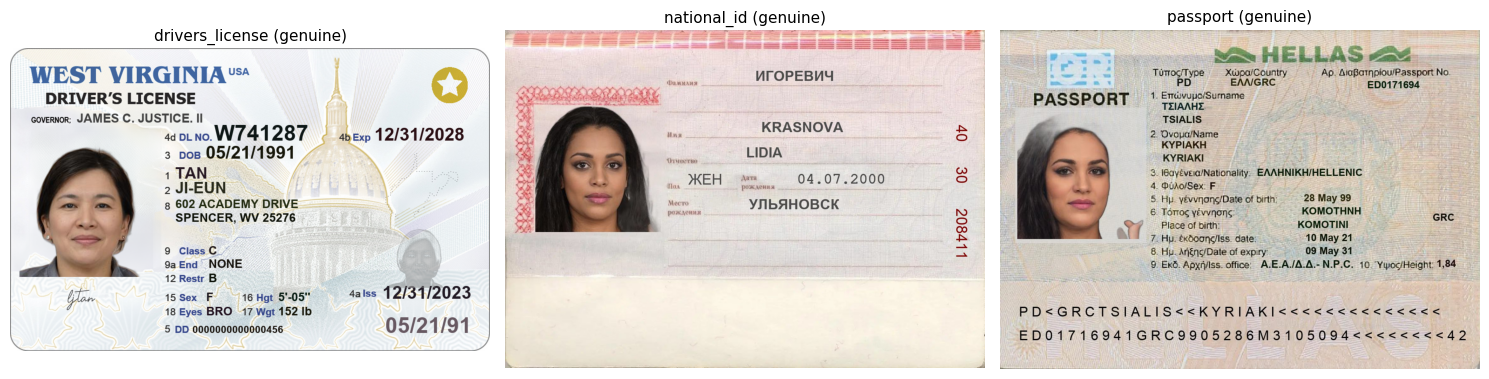

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, label in zip(axes, labels):
    matching = [f for f in all_files if f.startswith(label)]
    img = Image.open(os.path.join(raw_dir, matching[0]))
    ax.imshow(img)
    ax.set_title(f"{label} (genuine)", fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.show()

## **4. Synthetic Fake Generation**
### 4.1 Apply Gaussian blur to create fake subset

In [9]:
# Fake generation
# For each doc type: first 100 images stay genuine, next 100 become fakes.
# Fakes get one tampering method. Both genuine and fake images can also get
# "capture" effects (noise, lighting, jpeg) at the same rate, so the model
# can't just learn that noisy images are fake.

import random
random.seed(42)
np.random.seed(42)


# --- noise functions ---

def add_noise(img, sigma):
    # gaussian noise, basically camera grain
    noise = np.random.normal(0, sigma, img.shape)
    return np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)

def poisson_noise(img, scale=30):
    # noise that's stronger in brighter areas (low light photos)
    # smaller scale = more noise
    vals = np.clip(img.astype(np.float32) / 255.0 * scale, 0, None)
    return np.clip(np.random.poisson(vals) / scale * 255.0, 0, 255).astype(np.uint8)

def salt_pepper(img, amount=0.01):
    # random black and white pixels
    out = img.copy()
    mask = np.random.random(img.shape[:2])
    out[mask < amount / 2] = 0
    out[mask > 1 - amount / 2] = 255
    return out

def jpeg_compress(img, quality):
    # re-save as jpeg, lower quality = more compression artifacts
    ok, enc = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, quality])
    return cv2.imdecode(enc, cv2.IMREAD_COLOR)


# --- capture effects (used on both genuine and fake) ---

CAPTURE_RATE = 0.6  # same rate for both classes on purpose

def capture(img):
    # tries to look like someone took a photo of their ID and uploaded it
    if random.random() < 0.5:
        img = cv2.GaussianBlur(img, (3, 3), 0)  # slight blur, weaker than the fake blurs (5+)

    # small brightness/contrast change
    img = cv2.convertScaleAbs(img, alpha=random.uniform(0.85, 1.15), beta=random.randint(-20, 20))

    # one random noise type
    method = random.choice(["gaussian", "poisson", "saltpepper", "jpeg"])
    if method == "gaussian":
        img = add_noise(img, random.uniform(2, 15))
    elif method == "poisson":
        img = poisson_noise(img, scale=random.uniform(20, 60))
    elif method == "saltpepper":
        img = salt_pepper(img, random.uniform(0.001, 0.01))
    else:
        img = jpeg_compress(img, random.randint(50, 95))
    return img


# --- tampering methods (fakes only) ---
# each one returns (image, tag). tag goes in the filename so we can check
# later which types the models miss. no underscores in tags since we split on "_"

def rand_region(h, w, lo, hi):
    # random box inside the image, size is lo-hi fraction of height/width
    rh, rw = int(h * random.uniform(lo, hi)), int(w * random.uniform(lo, hi))
    return rh, rw, random.randint(0, h - rh), random.randint(0, w - rw)

def blur_full(img):
    # whole image blurred. kept low weight since this looks more like a bad photo than a fake
    k = random.choice([5, 7, 11, 15])
    return cv2.GaussianBlur(img, (k, k), 0), f"full{k}"

def blur_partial(img):
    # blur just one area
    k = random.choice([5, 7, 11, 15, 21])
    h, w = img.shape[:2]
    rh, rw, y, x = rand_region(h, w, 0.15, 0.35)
    out = img.copy()
    out[y:y+rh, x:x+rw] = cv2.GaussianBlur(img[y:y+rh, x:x+rw], (k, k), 0)
    return out, f"partial{k}"

def copy_move(img):
    # copy part of the card and paste it somewhere else on the same card
    h, w = img.shape[:2]
    rh, rw, y1, x1 = rand_region(h, w, 0.10, 0.25)
    y2, x2 = random.randint(0, h - rh), random.randint(0, w - rw)
    out = img.copy()
    out[y2:y2+rh, x2:x2+rw] = img[y1:y1+rh, x1:x1+rw]
    return out, "copymove"

def splice(img, donor):
    # paste a piece from a different card of the same type
    # (like swapping in someone else's photo)
    donor = cv2.resize(donor, (img.shape[1], img.shape[0]))  # same size so coords match
    h, w = img.shape[:2]
    rh, rw, y, x = rand_region(h, w, 0.15, 0.30)
    out = img.copy()
    out[y:y+rh, x:x+rw] = donor[y:y+rh, x:x+rw]
    return out, "splice"

def text_tamper(img):
    # cover a small strip and write a fake date over it
    h, w = img.shape[:2]
    scale = w / 1200  # images are ~1000-1500px wide, so scale text to fit

    y = random.randint(int(h * 0.3), int(h * 0.85))
    x = random.randint(int(w * 0.3), int(w * 0.6))
    color = tuple(int(c) for c in img[y, x])  # grab background color so the box blends in

    out = img.copy()
    cv2.rectangle(out, (x, y - int(30 * scale)), (x + int(220 * scale), y + int(8 * scale)), color, -1)
    cv2.putText(out, f"{random.randint(1, 28):02d}.{random.randint(1, 12):02d}.{random.randint(1950, 2005)}",
                (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.8 * scale, (30, 30, 30), max(1, int(2 * scale)))
    return out, "text"


# how often each tampering type gets picked
TAMPER_WEIGHTS = {"blur_full": 0.10, "blur_partial": 0.25, "copy_move": 0.20,
                  "splice": 0.25, "text": 0.20}

def make_fake(img, donor):
    # pick one tampering method based on the weights above
    choice = random.choices(list(TAMPER_WEIGHTS), weights=TAMPER_WEIGHTS.values())[0]
    if choice == "blur_full":      return blur_full(img)
    if choice == "blur_partial":   return blur_partial(img)
    if choice == "copy_move":      return copy_move(img)
    if choice == "splice":         return splice(img, donor)
    return text_tamper(img)


# --- build the dataset ---

output_dir = "/content/final_sample"
shutil.rmtree(output_dir, ignore_errors=True)  # clear old run
os.makedirs(output_dir, exist_ok=True)

for label in labels:
    matching = sorted(f for f in all_files if f.startswith(label))
    genuine_files = matching[:100]
    fake_files = matching[100:200]

    # genuine: no tampering, just maybe capture effects
    for f in genuine_files:
        img = cv2.imread(os.path.join(raw_dir, f))
        if random.random() < CAPTURE_RATE:
            img = capture(img)
        cv2.imwrite(os.path.join(output_dir, f"{label}_genuine_{f}"), img)

    # fake: tamper first, then maybe capture effects (same rate as genuine)
    for f in fake_files:
        img = cv2.imread(os.path.join(raw_dir, f))

        # donor for splice comes from the fake pool so genuine images don't leak into fakes
        donor_name = random.choice([d for d in fake_files if d != f])
        donor = cv2.imread(os.path.join(raw_dir, donor_name))

        fake, tag = make_fake(img, donor)
        if random.random() < CAPTURE_RATE:
            fake = capture(fake)

        cv2.imwrite(os.path.join(output_dir, f"{label}_fake_{tag}_{f}"), fake)

# check: should be 600 total, plus a count of each tampering type
print(f"Total in final_sample: {len(os.listdir(output_dir))}")
print(Counter(f.split("_fake_")[1].split("_")[0].rstrip("0123456789")  # "partial11" -> "partial"
              for f in os.listdir(output_dir) if "_fake_" in f))

Total in final_sample: 600
Counter({'splice': 79, 'partial': 68, 'copymove': 65, 'text': 60, 'full': 28})


### 4.2 Visualize genuine vs. fake side-by-side

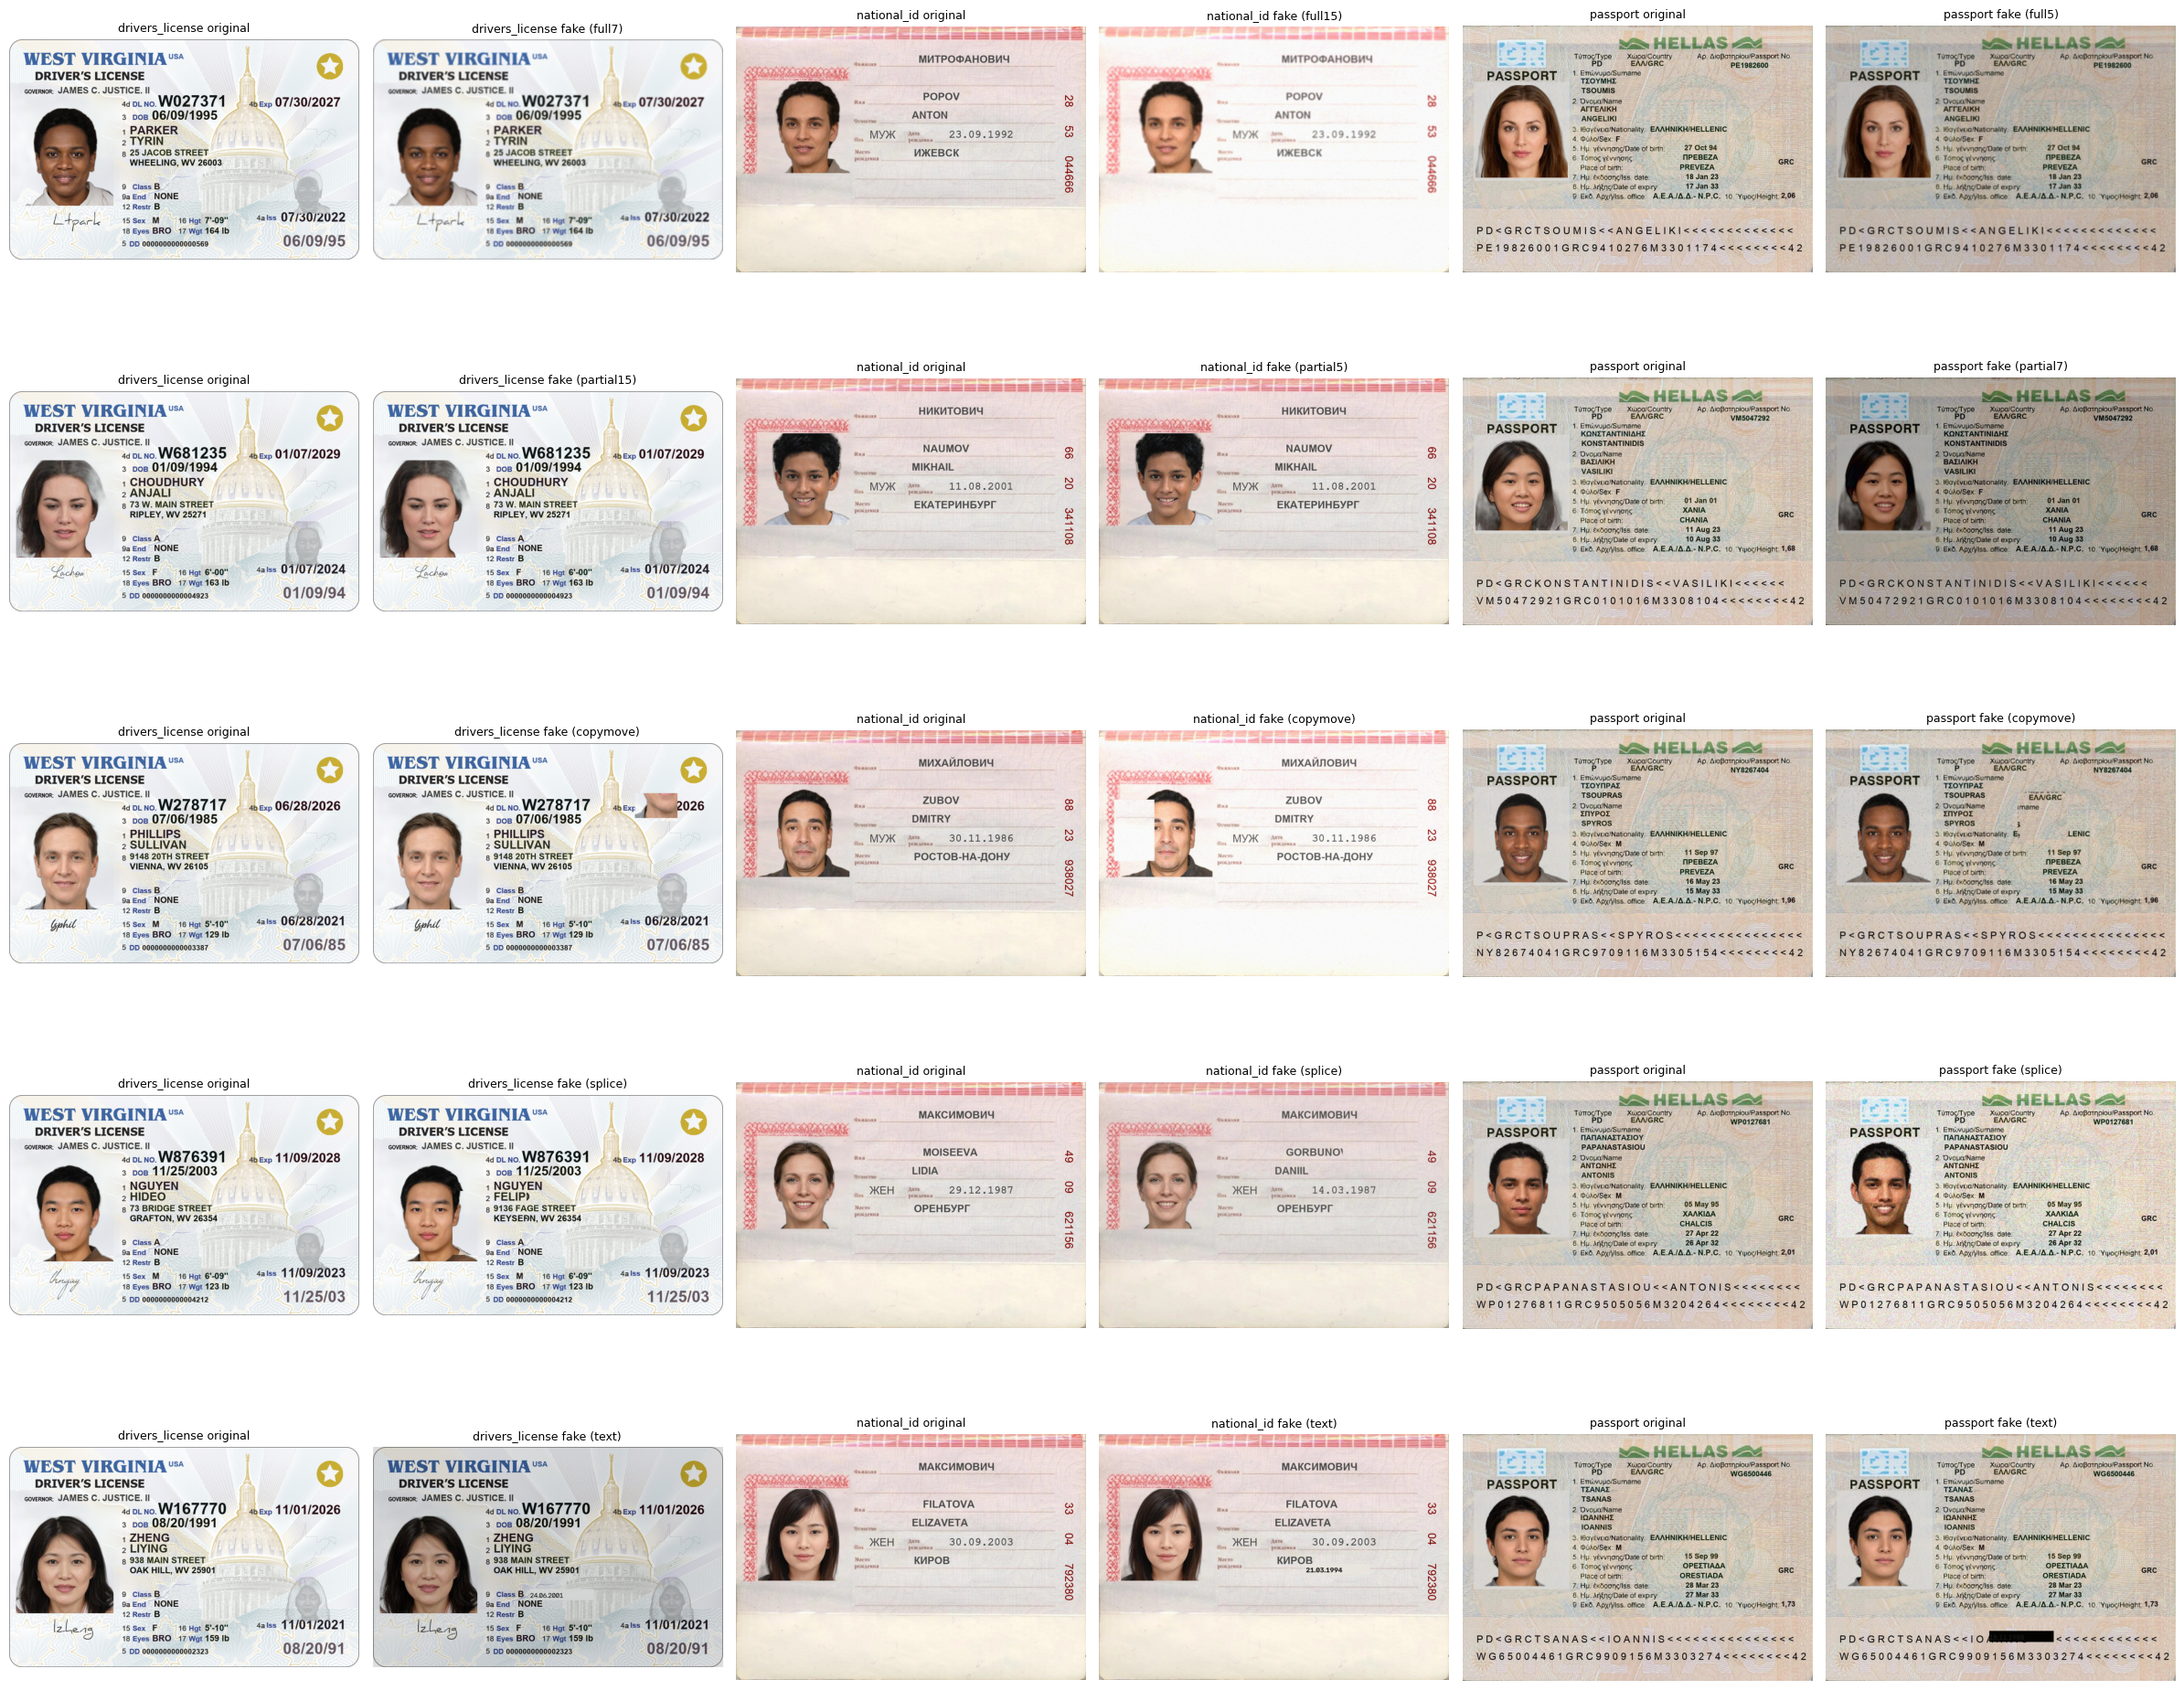

In [10]:
# show one example of each tampering type for each doc type, original next to the fake
fake_files = sorted(f for f in os.listdir(output_dir) if "_fake_" in f)
kinds = ["full", "partial", "copymove", "splice", "text"]

# rows = tampering type, columns = (original, fake) for each doc type
fig, axes = plt.subplots(len(kinds), len(labels) * 2, figsize=(24, 4 * len(kinds)))

for r, kind in enumerate(kinds):
    for c, label in enumerate(labels):
        ax_orig, ax_fake = axes[r, c * 2], axes[r, c * 2 + 1]
        ax_orig.axis("off")
        ax_fake.axis("off")

        options = [x for x in fake_files if x.startswith(f"{label}_fake_{kind}")]
        if not options:  # random weights might skip a type for some doc type
            ax_fake.set_title(f"{label}: no {kind} fakes", fontsize=9)
            continue

        f = random.choice(options)
        tag, original_name = f[len(f"{label}_fake_"):].split("_", 1)

        original = cv2.imread(os.path.join(raw_dir, original_name))
        fake = cv2.imread(os.path.join(output_dir, f))

        ax_orig.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
        ax_orig.set_title(f"{label} original", fontsize=9)
        ax_fake.imshow(cv2.cvtColor(fake, cv2.COLOR_BGR2RGB))
        ax_fake.set_title(f"{label} fake ({tag})", fontsize=9)

plt.tight_layout()
plt.show()

### 4.3 Confirm final_sample: 600 total, labeled genuine/fake

In [11]:
final_files = os.listdir(output_dir)
final_counts = Counter()

for f in final_files:
    for label in labels:
        for kind in ["genuine", "fake"]:
            if f.startswith(f"{label}_{kind}"):
                final_counts[f"{label}_{kind}"] += 1

for k, v in final_counts.items():
    print(f"{k}: {v}")
print(f"Total: {sum(final_counts.values())}")

drivers_license_fake: 100
national_id_genuine: 100
passport_genuine: 100
drivers_license_genuine: 100
national_id_fake: 100
passport_fake: 100
Total: 600


## 5. Feature extraction (HOG + LBP)

In [12]:
from skimage.feature import hog, local_binary_pattern

IMG_SIZE = (512, 320)  # (width, height)
GRID = 8               # split the card into an 8x8 grid for the local features

def grid_cells(arr, n=GRID):
    # yields each cell of an n x n grid over the image
    h, w = arr.shape[:2]
    for i in range(n):
        for j in range(n):
            yield arr[i*h//n:(i+1)*h//n, j*w//n:(j+1)*w//n]

def extract_features(path):
    img = cv2.imread(path)
    img = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # HOG: edge directions. bigger cells (32 instead of 16) so we have way fewer features
    hog_vec = hog(gray, orientations=9, pixels_per_cell=(32, 32), cells_per_block=(2, 2))

    # LBP: texture histogram per grid cell, so a small edited area still shows up
    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")
    lbp_vec = []
    for cell in grid_cells(lbp):
        hist, _ = np.histogram(cell, bins=10, range=(0, 10), density=True)
        lbp_vec.extend(hist)

    # noise residual: image minus a smoothed version leaves mostly noise.
    # pasted regions tend to have a different noise level than the rest of the card
    residual = gray.astype(np.float32) - cv2.medianBlur(gray, 3).astype(np.float32)
    noise_vec = [cell.std() for cell in grid_cells(residual)]

    # color: mean and std of each HSV channel per cell (4x4 is enough here).
    # splices can be a slightly different color than the area around them
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(np.float32)
    color_vec = []
    for cell in grid_cells(hsv, n=4):
        color_vec.extend(cell.reshape(-1, 3).mean(axis=0))
        color_vec.extend(cell.reshape(-1, 3).std(axis=0))

    # ELA: re-save as jpeg and see how much each cell changes.
    # edited areas often change more or less than untouched ones
    ok, enc = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 90])
    resaved = cv2.imdecode(enc, cv2.IMREAD_COLOR)
    ela = cv2.absdiff(img, resaved).astype(np.float32).mean(axis=2)
    ela_vec = [cell.mean() for cell in grid_cells(ela)]

    parts = {"hog": hog_vec, "lbp": lbp_vec, "noise": noise_vec, "color": color_vec, "ela": ela_vec}
    return np.concatenate([np.asarray(v, dtype=np.float32) for v in parts.values()]), parts

files = sorted(os.listdir(output_dir))
feats = [extract_features(os.path.join(output_dir, f)) for f in files]
X = np.array([vec for vec, _ in feats])
y = np.array([1 if "_fake_" in f else 0 for f in files])          # 1 = fake, 0 = genuine
doc_type = np.array([next(l for l in labels if f.startswith(l)) for f in files])

# keep track of which columns belong to which feature group (for feature importance later)
feature_groups, start = {}, 0
for name, v in feats[0][1].items():
    feature_groups[name] = slice(start, start + len(v))
    start += len(v)

print("Feature matrix:", X.shape)
for name, s in feature_groups.items():
    print(f"  {name}: {s.stop - s.start} features")
print("Fake:", y.sum(), "| Genuine:", len(y) - y.sum())

Feature matrix: (600, 5724)
  hog: 4860 features
  lbp: 640 features
  noise: 64 features
  color: 96 features
  ela: 64 features
Fake: 300 | Genuine: 300


## 6. Train / Test Split (80-20)

In [13]:
from sklearn.model_selection import train_test_split

def tamper_type(f):
    # "genuine" for real images, otherwise the tampering tag without the blur size
    if "_fake_" not in f:
        return "genuine"
    return f.split("_fake_")[1].split("_")[0].rstrip("0123456789")

# stratify by doc type + tampering type, so train and test get the same mix
strata = [f"{d}_{tamper_type(f)}" for d, f in zip(doc_type, files)]

X_train, X_test, y_train, y_test, f_train, f_test = train_test_split(
    X, y, np.array(files), test_size=0.2, stratify=strata, random_state=42
)
print("Train:", len(y_train), "| Test:", len(y_test))
print("Test mix:", Counter(tamper_type(f) for f in f_test))

Train: 480 | Test: 120
Test mix: Counter({'genuine': 60, 'splice': 15, 'partial': 14, 'copymove': 14, 'text': 12, 'full': 5})


## 7. Model Training

### 7.1 Initial models: Logistic Regression, SVM, Random Forest

In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

N_PCA = 200  # cut features down to 200 to reduce overfitting

models = {
    # scale, then PCA, then the model
    # lower C = simpler model
    "Logistic Regression": make_pipeline(StandardScaler(), PCA(n_components=N_PCA, random_state=42),
                                         LogisticRegression(C=0.1, max_iter=2000)),
    "SVM (Linear)":        make_pipeline(StandardScaler(), PCA(n_components=N_PCA, random_state=42),
                                         SVC(kernel="linear", C=0.1, probability=True, random_state=42)),
    "SVM (RBF)":           make_pipeline(StandardScaler(), PCA(n_components=N_PCA, random_state=42),
                                         SVC(kernel="rbf", C=1.0, probability=True, random_state=42)),

    # no PCA here so we can still check feature importance later
    # min_samples_leaf stops it from memorizing single images
    "Random Forest":       RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                  max_features="sqrt", n_jobs=-1, random_state=42),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    print(f"{name}: train acc {m.score(X_train, y_train):.3f}")  # check if still at 1.000

Logistic Regression: train acc 0.875
SVM (Linear): train acc 0.910
SVM (RBF): train acc 0.750
Random Forest: train acc 1.000


### 7.2 Additional models: Decision Tree, Extra Trees, AdaBoost, Gradient Boosting

In [15]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import ExtraTreesClassifier, AdaBoostClassifier, HistGradientBoostingClassifier

# tree-based models, so no scaling or PCA needed
# each one has a few limits added since they were all hitting 100% train accuracy before
new_models = {
    # single tree, capped at depth 8 so it can't keep splitting until every image is memorized
    "Decision Tree":     DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, random_state=42),

    # like random forest but with more random splits, same limits as RF
    "Extra Trees":       ExtraTreesClassifier(n_estimators=300, min_samples_leaf=3,
                                              max_features="sqrt", n_jobs=-1, random_state=42),

    # lower learning rate so each new model only fixes a little of the previous mistakes
    "AdaBoost":          AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=42),

    # shallow trees + L2 penalty, and early stopping quits once the validation score stops improving
    "Gradient Boosting": HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05,
                                                        l2_regularization=1.0, early_stopping=True,
                                                        random_state=42),
}

# train each model and print train accuracy to see if it's still overfitting
for name, m in new_models.items():
    m.fit(X_train, y_train)
    print(f"{name}: train acc {m.score(X_train, y_train):.3f}")

Decision Tree: train acc 0.827
Extra Trees: train acc 1.000
AdaBoost: train acc 0.871
Gradient Boosting: train acc 0.854


** 7.3 More models: MLP (DNN), KNN, Naive Bayes, LDA, XGBoost, LightGBM**

In [17]:
# 7.3 More models
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

K_BEST = 300  # keep the 300 features most related to genuine vs fake

extra_models = {
    # small neural net, more patience before early stopping
    "MLP (DNN)":   make_pipeline(StandardScaler(), SelectKBest(f_classif, k=K_BEST),
                                 MLPClassifier(hidden_layer_sizes=(128, 64), alpha=1e-3,
                                               early_stopping=True, validation_fraction=0.2,
                                               n_iter_no_change=30, max_iter=1000, random_state=42)),

    # these need fewer features, so pick the most useful ones first
    "KNN":         make_pipeline(StandardScaler(), SelectKBest(f_classif, k=K_BEST),
                                 KNeighborsClassifier(n_neighbors=7)),
    "Naive Bayes": make_pipeline(StandardScaler(), SelectKBest(f_classif, k=K_BEST),
                                 GaussianNB()),
    "LDA":         make_pipeline(StandardScaler(), SelectKBest(f_classif, k=K_BEST),
                                 LinearDiscriminantAnalysis()),

    # boosting, no feature reduction needed
    "XGBoost":     XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                 subsample=0.8, colsample_bytree=0.3, eval_metric="logloss",
                                 random_state=42),
    "LightGBM":    LGBMClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.3,
                                  verbose=-1, random_state=42),
}

for name, m in extra_models.items():
    m.fit(X_train, y_train)
    print(f"{name}: train acc {m.score(X_train, y_train):.3f}")

MLP (DNN): train acc 0.812
KNN: train acc 0.646
Naive Bayes: train acc 0.627
LDA: train acc 0.952
XGBoost: train acc 1.000
LightGBM: train acc 1.000


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


### 7.3 Join Models

In [18]:
all_models = {**models, **new_models, **extra_models}   # teammates add their dicts here, e.g. **teammate_models
print(len(all_models), "models:", list(all_models))

14 models: ['Logistic Regression', 'SVM (Linear)', 'SVM (RBF)', 'Random Forest', 'Decision Tree', 'Extra Trees', 'AdaBoost', 'Gradient Boosting', 'MLP (DNN)', 'KNN', 'Naive Bayes', 'LDA', 'XGBoost', 'LightGBM']


## 8. Model Evaluation

### 8.1 Metrics comparison (all models)

In [19]:
import pandas as pd
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

rows = []
for name, m in all_models.items():
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "Train acc": m.score(X_train, y_train),
    })

results = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)
results["Gap (train − test)"] = results["Train acc"] - results["Accuracy"]
results.round(3)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train acc,Gap (train − test)
0,XGBoost,0.675,0.684,0.650,0.667,0.702,1.000,0.325
1,Random Forest,0.642,0.639,0.650,0.645,0.672,1.000,0.358
2,Naive Bayes,0.633,0.767,0.383,0.511,0.683,0.627,-0.006
3,AdaBoost,0.625,0.667,0.500,0.571,0.671,0.871,0.246
4,LightGBM,0.625,0.623,0.633,0.628,0.696,1.000,0.375
5,Logistic Regression,0.625,0.632,0.600,0.615,0.686,0.875,0.250
6,SVM (Linear),0.617,0.617,0.617,0.617,0.695,0.910,0.294
7,Extra Trees,0.592,0.596,0.567,0.581,0.643,1.000,0.408
8,MLP (DNN),0.575,0.563,0.667,0.611,0.604,0.812,0.238
9,Gradient Boosting,0.550,0.556,0.500,0.526,0.611,0.854,0.304


### 8.2 Confusion matrices

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


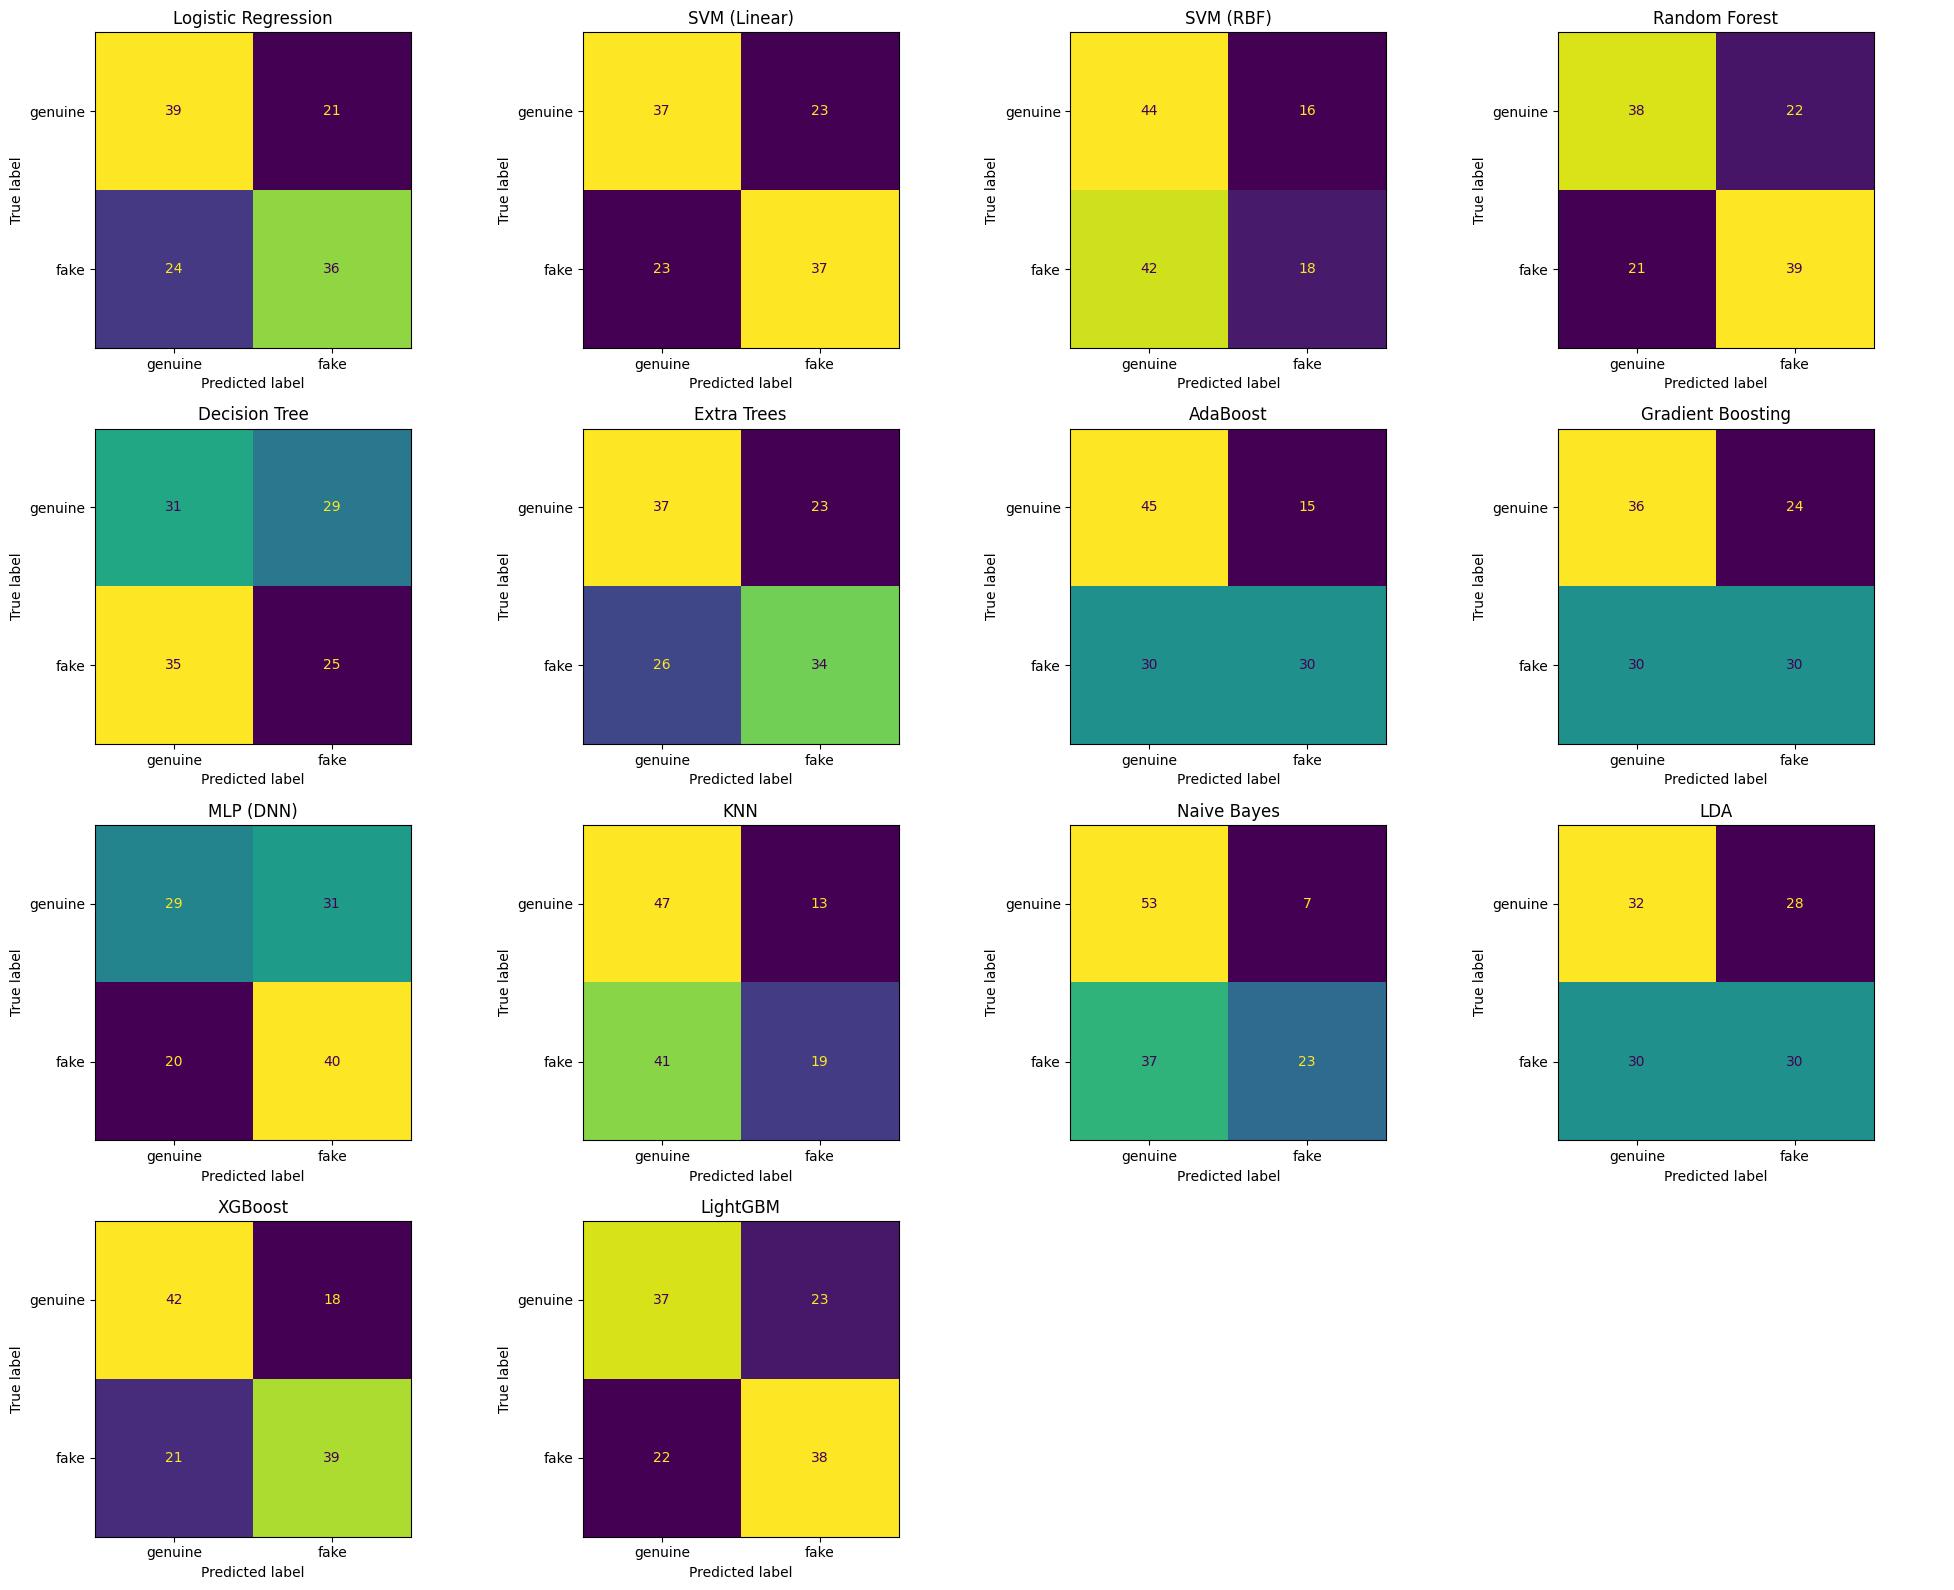

In [20]:
import math
from sklearn.metrics import ConfusionMatrixDisplay

n_cols = 4
n_rows = math.ceil(len(all_models) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
for ax, (name, m) in zip(axes.flat, all_models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test,
                                          display_labels=["genuine", "fake"],
                                          ax=ax, colorbar=False)
    ax.set_title(name)
for ax in axes.flat[len(all_models):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 8.3 Fakes caught by type (full vs. partial blur)

In [21]:
for name, m in all_models.items():
    pred = m.predict(X_test)
    for kind in ["full", "partial"]:
        mask = np.array([f"_fake_{kind}" in f for f in f_test])
        print(f"{name:20s} {kind:8s} fakes caught: {pred[mask].mean():.0%} ({mask.sum()} images)")

Logistic Regression  full     fakes caught: 100% (5 images)
Logistic Regression  partial  fakes caught: 64% (14 images)
SVM (Linear)         full     fakes caught: 100% (5 images)
SVM (Linear)         partial  fakes caught: 57% (14 images)
SVM (RBF)            full     fakes caught: 100% (5 images)
SVM (RBF)            partial  fakes caught: 14% (14 images)
Random Forest        full     fakes caught: 100% (5 images)
Random Forest        partial  fakes caught: 79% (14 images)
Decision Tree        full     fakes caught: 80% (5 images)
Decision Tree        partial  fakes caught: 57% (14 images)
Extra Trees          full     fakes caught: 100% (5 images)
Extra Trees          partial  fakes caught: 50% (14 images)
AdaBoost             full     fakes caught: 100% (5 images)
AdaBoost             partial  fakes caught: 50% (14 images)
Gradient Boosting    full     fakes caught: 100% (5 images)
Gradient Boosting    partial  fakes caught: 43% (14 images)
MLP (DNN)            full     fakes caugh

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


### 8.4 Confusion counts (TP / FN / FP / TN)

In [22]:
from sklearn.metrics import confusion_matrix

for name, m in all_models.items():
    tn, fp, fn, tp = confusion_matrix(y_test, m.predict(X_test)).ravel()
    print(f"{name:20s} TP {tp} | FN {fn} | FP {fp} | TN {tn}")

Logistic Regression  TP 36 | FN 24 | FP 21 | TN 39
SVM (Linear)         TP 37 | FN 23 | FP 23 | TN 37
SVM (RBF)            TP 18 | FN 42 | FP 16 | TN 44
Random Forest        TP 39 | FN 21 | FP 22 | TN 38
Decision Tree        TP 25 | FN 35 | FP 29 | TN 31
Extra Trees          TP 34 | FN 26 | FP 23 | TN 37
AdaBoost             TP 30 | FN 30 | FP 15 | TN 45
Gradient Boosting    TP 30 | FN 30 | FP 24 | TN 36
MLP (DNN)            TP 40 | FN 20 | FP 31 | TN 29
KNN                  TP 19 | FN 41 | FP 13 | TN 47
Naive Bayes          TP 23 | FN 37 | FP 7 | TN 53
LDA                  TP 30 | FN 30 | FP 28 | TN 32
XGBoost              TP 39 | FN 21 | FP 18 | TN 42
LightGBM             TP 38 | FN 22 | FP 23 | TN 37


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


### 8.5 Cross-validation

In [23]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
import pandas as pd

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for name, m in all_models.items():
    scores = cross_val_score(m, X, y, cv=cv, scoring="accuracy")
    cv_rows.append({"Model": name, "CV accuracy": scores.mean(), "Std": scores.std()})
    print(f"{name:20s} {scores.mean():.3f} ± {scores.std():.3f}")

pd.DataFrame(cv_rows).sort_values("CV accuracy", ascending=False).reset_index(drop=True).round(3)

Logistic Regression  0.548 ± 0.025
SVM (Linear)         0.567 ± 0.027
SVM (RBF)            0.543 ± 0.028
Random Forest        0.567 ± 0.033
Decision Tree        0.570 ± 0.032
Extra Trees          0.575 ± 0.021
AdaBoost             0.608 ± 0.057
Gradient Boosting    0.598 ± 0.025
MLP (DNN)            0.575 ± 0.037
KNN                  0.540 ± 0.032
Naive Bayes          0.575 ± 0.030
LDA                  0.553 ± 0.023
XGBoost              0.582 ± 0.037


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM             0.577 ± 0.039


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,CV accuracy,Std
0,AdaBoost,0.608,0.057
1,Gradient Boosting,0.598,0.025
2,XGBoost,0.582,0.037
3,LightGBM,0.577,0.039
4,Extra Trees,0.575,0.021
5,Naive Bayes,0.575,0.030
6,MLP (DNN),0.575,0.037
7,Decision Tree,0.570,0.032
8,SVM (Linear),0.567,0.027
9,Random Forest,0.567,0.033


## 9. Demo: Classify an Uploaded Image

In [ ]:
def predict_image(path):
    feats = extract_features(path).reshape(1, -1)
    results = []
    for name, m in all_models.items():
        p = m.predict_proba(feats)[0, 1]          # probability of fake
        verdict = "FAKE" if p >= 0.5 else "GENUINE"
        results.append(f"{name}: {verdict} ({p:.0%} fake)")
    return results

In [ ]:
from google.colab import files as colab_files

uploaded = colab_files.upload()

for name in uploaded:
    path = f"/content/{name}"
    if cv2.imread(path) is None:
        print(f"{name}: couldn't read it. Use a .jpg or .png file.")
        continue

    feats = extract_features(path).reshape(1, -1)
    probs = {}
    print(name)
    for model_name, m in all_models.items():
        p_fake = m.predict_proba(feats)[0, 1]
        probs[model_name] = p_fake
        verdict = "FAKE" if p_fake >= 0.5 else "GENUINE"
        print(f"  {model_name:20s} {verdict:8s} genuine {1 - p_fake:.0%} | fake {p_fake:.0%}")

    avg = np.mean(list(probs.values()))
    final = "FAKE" if avg >= 0.5 else "GENUINE"
    print(f"  FINAL (average)      {final:8s} genuine {1 - avg:.0%} | fake {avg:.0%}")

    plt.figure(figsize=(8, 5))
    plt.imshow(cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB))
    plt.title(f"{final}: genuine {1 - avg:.0%} | fake {avg:.0%}")
    plt.axis("off")
    plt.show()